# Trials with pynapple

Many experiments are organized into trials separated by gaps, and we often want to fit a model using only the data within those trials. When the model includes event history, this raises a question about how to handle trial boundaries. Simply extracting the trial data and joining them into one array makes the end of one trial and the start of the next appear to be consecutive samples. Convolution then carries event history from one trial into the next, ignoring the time that elapsed between them.

To preserve those boundaries, we can use [`pynapple`](https://pynapple.org) objects, which both `nemos` and `pgam_jax` accept in place of arrays. Along with timestamps and values, a pynapple time series stores its `time_support`: the intervals over which observations are valid. Setting this support to the trial intervals allows convolution to run separately within each trial. If the inputs are also recorded during the gaps, another option is to convolve over the continuous recording while using only the trial responses to fit the model.

In this notebook, we will start with raw arrays from a simulated recording and demonstrate what goes wrong when trials are concatenated before convolution. We will then use pynapple to implement both solutions and compare how much trial data each retains. For both fits, we will use the position and event model from [notebook 02](02_fit_position_and_event_smooths.ipynb), leaving out the nuisance input:

$$\log \lambda_t = \beta_0 + f_{\mathrm{pos}}(x_t) + \sum_{\tau \ge 0} k(\tau)\, e_{t-\tau}$$

$$y_t \sim \mathrm{Poisson}(\lambda_t)$$

Here, the spike count $y_t$ in each time bin depends on position $x_t$ through the smooth $f_{\mathrm{pos}}$, and on past event counts $e_t$ through the response kernel $k$. The model gives the expected count per bin, $\lambda_t$, which we divide by the bin width to obtain a firing rate in spikes/s.

We simulate events only within trials and leave gaps longer than the event response, so no response carries over into the next trial in the underlying recording. This makes any carryover introduced by concatenating the trials easy to distinguish from the true event history.

In [1]:
import jax
import nemos as nmo
import numpy as np
import pynapple as nap
from example_data import (
    EVENT_WINDOW_SIZE,
    TIME_BIN,
    make_event_impulse,
    make_trial_recording,
)
from example_plots import (
    hide_file_paths_in_warnings,
    plot_design_at_trial_border,
    plot_predicted_and_true_rate_in_trials,
    plot_recovered_smooths,
    plot_trials,
    set_plot_style,
)

from pgam_jax import GAM

jax.config.update("jax_enable_x64", True)
set_plot_style()
hide_file_paths_in_warnings()

Unable to revert mtime: /Library/Fonts


Matplotlib is building the font cache; this may take a moment.


## The raw data

The simulated recording lasts about 160 seconds and contains 20 trials. Trial durations range from 4 to 8 seconds, with a 2 second gap after each trial.

The data arrive as plain arrays:

* position values and their timestamps, sampled every 10 ms
* event timestamps
* spike timestamps
* the start and end of each trial

All timestamps are in seconds. Position and spikes are recorded throughout, including the gaps. Event recording also covers the whole recording, but no events occur in the gaps.

In [2]:
data = make_trial_recording()

for name in [
    "position_time",
    "position",
    "event_times",
    "spike_times",
    "trial_starts",
    "trial_ends",
]:
    label = f"Shape of data.{name}:"
    print(f"{label:<29}{getattr(data, name).shape}")

Shape of data.position_time: (15900,)
Shape of data.position:      (15900,)
Shape of data.event_times:   (180,)
Shape of data.spike_times:   (6176,)
Shape of data.trial_starts:  (20,)
Shape of data.trial_ends:    (20,)


## Convert the raw data into pynapple objects

* The trials become a `nap.IntervalSet`: a set of time intervals, each with a start and an end.
* Position becomes a `nap.Tsd`: a time series with one value at each timestamp.
* Events and spikes become `nap.Ts` objects: timestamps with no values.

In [3]:
trials = nap.IntervalSet(start=data.trial_starts, end=data.trial_ends)
position = nap.Tsd(t=data.position_time, d=data.position)
events = nap.Ts(t=data.event_times)
spikes = nap.Ts(t=data.spike_times)

trials

index    start    end
0        0.0      5.0
1        7.0      14.0
2        16.0     20.6
3        22.6     28.7
4        30.7     36.3
5        38.3     46.1
6        48.1     55.9
...      ...      ...
13       103.9    109.3
14       111.3    117.4
15       119.4    125.7
16       127.7    135.4
17       137.4    143.1
18       145.1    149.9
19       151.9    157.0
shape: (20, 2), time unit: sec.

The first 3 trials. The tinted bands are the trials. Position and spikes continue in the gaps, but the events happen only inside the trials.

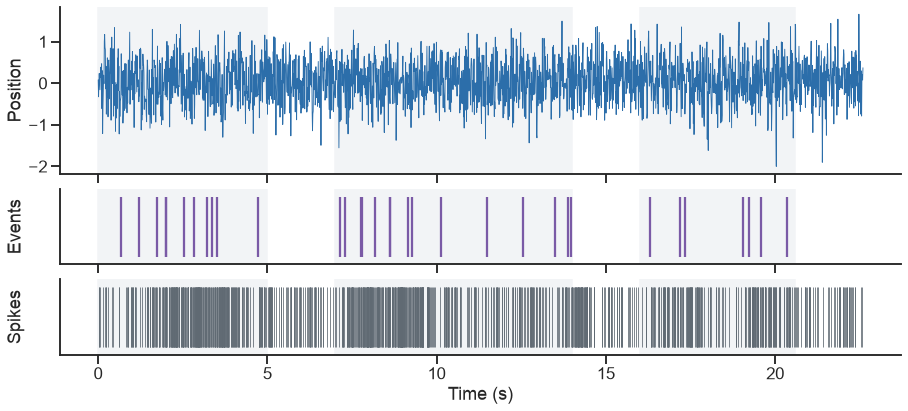

In [4]:
fig, ax = plot_trials(trials, position, events, spikes)

## Build the model inputs

The model needs position, event counts, and spike counts on the same time bins. We bin all three series using a width of `TIME_BIN` seconds. Passing `ep=trials` limits the bins to the trial intervals.

* `bin_average` averages the position samples in each bin.
* `count` counts the events or spikes in each bin.

Each result is a `nap.Tsd`, with timestamps at the bin centers and the trials as its `time_support`. We check that all three results have the same timestamps.

In [5]:
position_binned = position.bin_average(TIME_BIN, ep=trials)
event_counts = events.count(TIME_BIN, ep=trials)
spike_counts = spikes.count(TIME_BIN, ep=trials)

print(f"Time bins in the trials: {len(spike_counts)}")
print(
    "Same time bins: "
    f"{np.array_equal(position_binned.t, event_counts.t)}, "
    f"{np.array_equal(event_counts.t, spike_counts.t)}"
)
spike_counts.time_support

Time bins in the trials: 11900
Same time bins: True, True


index    start    end
0        0.0      5.0
1        7.0      14.0
2        16.0     20.6
3        22.6     28.7
4        30.7     36.3
5        38.3     46.1
6        48.1     55.9
...      ...      ...
13       103.9    109.3
14       111.3    117.4
15       119.4    125.7
16       127.7    135.4
17       137.4    143.1
18       145.1    149.9
19       151.9    157.0
shape: (20, 2), time unit: sec.

## Build the basis

The same bases as in notebook 02, without the nuisance input.

In [6]:
position_basis = nmo.basis.BSplineEval(
    11,
    bounds=(-2.0, 2.0),
    label="position",
)
event_basis = nmo.basis.BSplineConv(
    8,
    window_size=EVENT_WINDOW_SIZE,  # in bins
    label="event history",
)

full_basis = position_basis + event_basis

## Compare convolution with and without trial boundaries

We build the same design matrix from two representations of the binned data:

* Plain arrays carry no trial information. Convolution treats the end of one trial and the start of the next as consecutive samples.
* Pynapple objects preserve the trial intervals, so convolution runs separately within each trial.

In [7]:
design_joined = full_basis.compute_features(position_binned.values, event_counts.values)
design_split = full_basis.compute_features(position_binned, event_counts)

print(type(design_split))
print(f"Design matrix shape: {design_split.shape}")

<class 'pynapple.core.time_series.TsdFrame'>
Design matrix shape: (11900, 19)


The plot shows the design around one trial boundary, with time on the vertical axis. The hatched band marks the gap, where neither design has rows. An event near the end of the first trial makes the difference visible:

* With arrays, its history carries into the next trial, even though its response ended during the gap in the actual recording.
* With pynapple, the first `EVENT_WINDOW_SIZE` rows of the next trial have NaN event features, shown in orange. The position features remain defined, but the event features lack a full window of history within that trial.

`GAM` offers two ways to handle these NaNs. The default, `nan_handling="zero"`, replaces missing feature values with zero and keeps the rows. With `nan_handling="drop"`, any row containing a NaN feature is excluded from the fit.

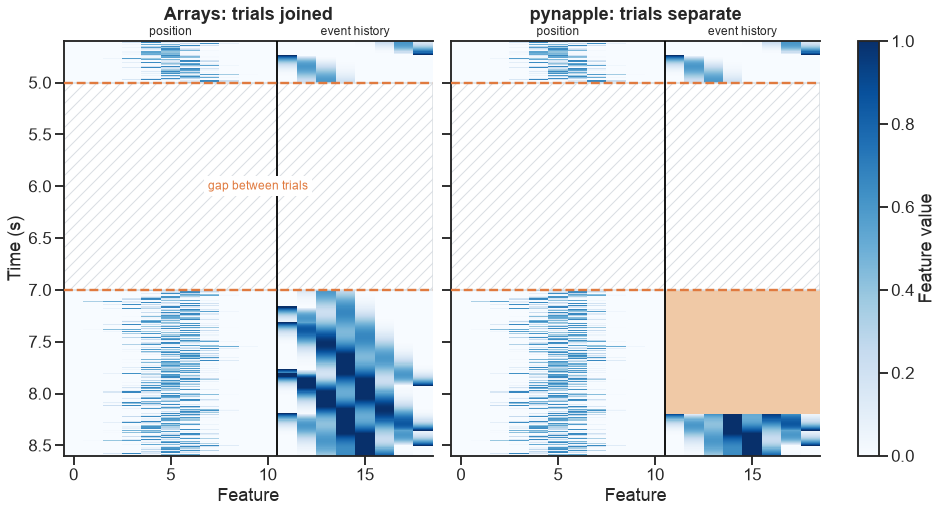

In [8]:
fig, ax = plot_design_at_trial_border(full_basis, design_joined, design_split)

## Fit the GAM

We pass the pynapple inputs and spike counts directly to `fit` and use `nan_handling="drop"`.

Zero filling would assign zero event features throughout the first 1.2 seconds of each trial, including bins where early events already affect the firing rate. This mismatch can bias the fitted smooths. Dropping these rows avoids fitting spikes against an incomplete event history.

The cost is substantial for short trials: 120 bins per trial, or 2,400 of the 11,900 trial bins here. Later, we will use the continuous recording to recover most of these bins.

In [9]:
gam = GAM(
    full_basis,
    use_scipy=True,  # can be faster on CPU
    nan_handling="drop",
)
gam.fit((position_binned, event_counts), spike_counts)

## Compare the fitted smooths with the truth

We evaluate the position smooth on a position grid and the event smooth using a single event impulse, as in notebook 02. The shaded bands are the default 95% confidence bands returned by `smooth_compute`.

The fitted curves capture the main shapes of the true effects, with larger differences near the position boundaries. These plots compare the estimated effects with the known simulation truth.

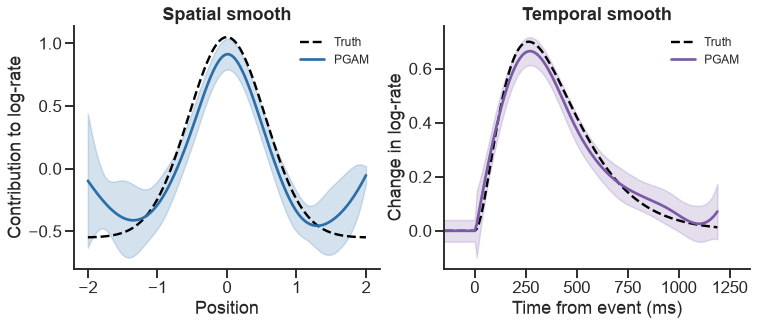

In [10]:
value_grid = np.linspace(-2.0, 2.0, 400)
position_smooth = gam.smooth_compute(value_grid, "position")

# evaluate the temporal smooth in response to a single event
impulse, event_time_ms = make_event_impulse()
event_smooth = gam.smooth_compute(impulse, "event history")

fig, ax = plot_recovered_smooths(
    value_grid,
    position_smooth=position_smooth,
    nuisance_smooth=None,
    event_smooth=event_smooth,
    impulse=impulse,
    event_time_ms=event_time_ms,
)

## Predict the firing rate within trials

`gam.predict` accepts pynapple inputs and returns a `Tsd` with their timestamps and time support. Dividing the predicted counts by `TIME_BIN` converts them to spikes/s.

Prediction preserves the input rows. With `nan_handling="drop"`, it returns NaN where the event features are undefined, leaving the first 1.2 seconds of each trial blank in the plot.

We show predictions for the first two training trials alongside the known firing rate. This illustrates the fitted model, rather than its performance on held-out data.

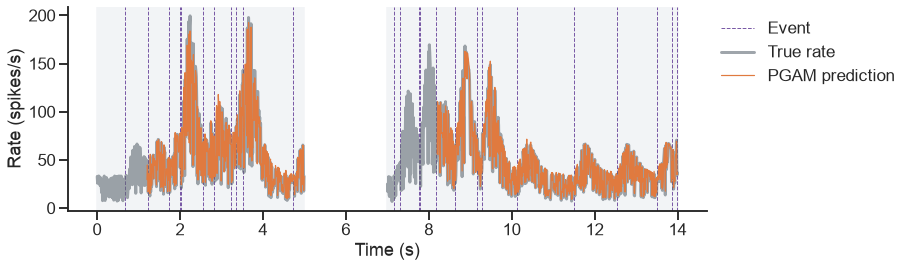

In [11]:
# Divide by the bin width to convert the count per bin to spikes/s.
predicted_rate = gam.predict((position_binned, event_counts)) / TIME_BIN
true_rate = nap.Tsd(t=data.position_time, d=data.true_rate)

fig, ax = plot_predicted_and_true_rate_in_trials(
    trials, events, true_rate, predicted_rate
)

## Use continuous history while fitting only the trials

So far, each trial has been treated as a separate observation interval. In this recording, however, the inputs are also known during the gaps. In particular, we know that no events occurred there. We can use that history to construct event features at the start of each trial.

We bin the whole recording and convolve over that continuous interval. To keep the fit limited to trial responses, we set spike counts outside the trials to NaN. `GAM.fit` excludes those response rows while still using the input history from the gaps.

This requires valid input history between trials. If event logging stops during the gaps, an empty event list does not establish that no events occurred. In that case, treating the missing history as zero would be an unsupported assumption.

In [12]:
# One interval for the whole recording gives all inputs the same bins.
# The position samples are at the bin centers.
recording = nap.IntervalSet(start=0.0, end=data.position_time[-1] + TIME_BIN / 2)

position_rec = position.bin_average(TIME_BIN, ep=recording)
event_counts_rec = events.count(TIME_BIN, ep=recording)
spike_counts_rec = spikes.count(TIME_BIN, ep=recording)

# in_interval gives NaN for the bins outside the trials.
in_trial = ~np.isnan(trials.in_interval(spike_counts_rec))
# set the time series data to NaN outside the trials
spike_counts_in_trials = nap.Tsd(
    t=spike_counts_rec.t,
    d=np.where(in_trial, spike_counts_rec.values, np.nan),
    time_support=spike_counts_rec.time_support,  # required for equivalence check
)

We build the continuous design explicitly to compare it with the earlier designs at the same trial boundary.

The third panel includes rows in the gap. The earlier event's response ends there, leaving no contribution from that event at the next trial's start. New events early in the next trial have defined features, where the separate-trial design has NaNs.

The timestamp check confirms that the continuous and separate-trial binning align inside the trials for this example. The simulated trial boundaries fall on the common bin grid.

Same rows inside the trials: True


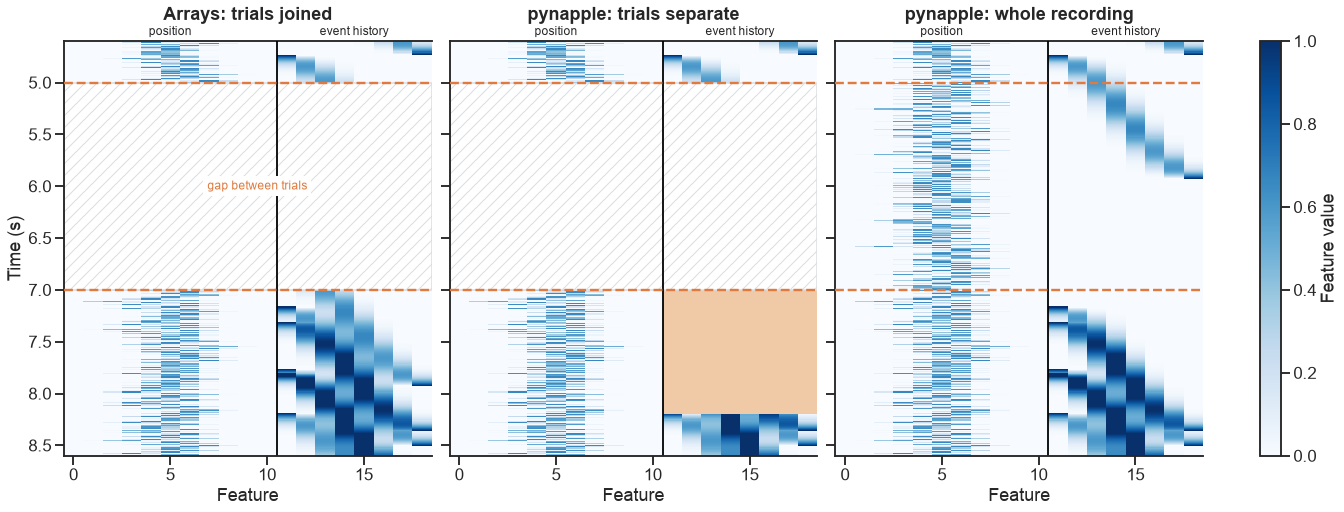

In [13]:
design_rec = full_basis.compute_features(position_rec, event_counts_rec)
print(
    "Same rows inside the trials: "
    f"{np.array_equal(design_rec.restrict(trials).t, design_split.t)}"
)

fig, ax = plot_design_at_trial_border(
    full_basis, design_joined, design_split, design_rec
)

Fit using the continuous inputs and the masked spike counts. History comes from the whole recording, but only responses inside trials contribute to the fit.

In [14]:
gam_rec = GAM(
    full_basis,
    use_scipy=True,
    nan_handling="drop",
)
gam_rec.fit((position_rec, event_counts_rec), spike_counts_in_trials)

Only the first trial still loses its first 1.2 seconds, because no recorded history precedes it. The separate-trial fit uses 9,500 bins. Continuous history increases this to 11,780 bins, recovering 2,280 bins, or 22.8 seconds of trial data.

We count valid predictions within trials to check these totals. The response mask controls fitting only: predictions outside trials are still defined wherever the input history is valid.

We predict over the continuous recording before restricting the result to trials, so the convolution still uses the history in the gaps. The plot shows the predictions recovered near the start of the second trial.

Rows in the fit, trials convolved separately: 9500
Rows in the fit, whole recording convolved:   11780


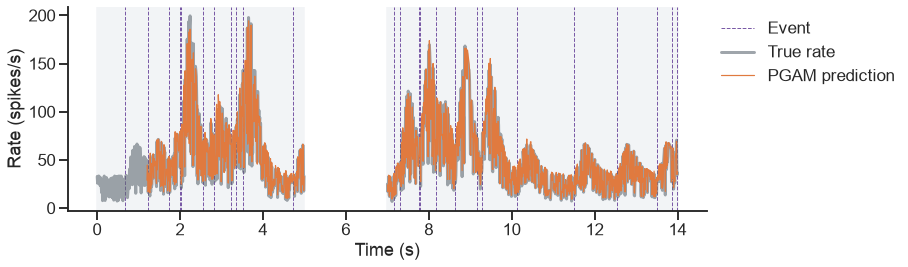

In [15]:
# Predict with continuous history, then select the trial intervals.
predicted_rate_rec = (
    gam_rec.predict((position_rec, event_counts_rec)) / TIME_BIN
).restrict(trials)

rows_split = np.isfinite(predicted_rate.values).sum()
rows_rec = np.isfinite(predicted_rate_rec.values).sum()
print(f"Rows in the fit, trials convolved separately: {rows_split}")
print(f"Rows in the fit, whole recording convolved:   {rows_rec}")

fig, ax = plot_predicted_and_true_rate_in_trials(
    trials, events, true_rate, predicted_rate_rec
)

### Compare the smooths after retaining more trial data

We use the same grids and plotting conventions to inspect the second fit. Retaining more trial data does not guarantee that every part of each estimated curve will move closer to the truth.

The choice between the two approaches depends on the available history. When inputs outside trials are unavailable, keep trials separate and exclude bins without a full history window. When continuous inputs are known, use them to build the history and mask the responses to select the bins used for fitting.

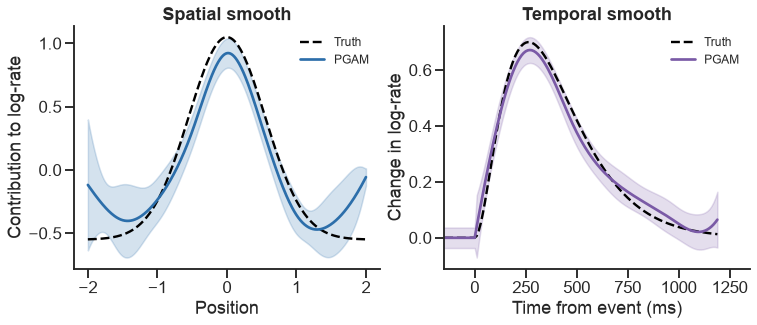

In [16]:
fig, ax = plot_recovered_smooths(
    value_grid,
    position_smooth=gam_rec.smooth_compute(value_grid, "position"),
    nuisance_smooth=None,
    event_smooth=gam_rec.smooth_compute(impulse, "event history"),
    impulse=impulse,
    event_time_ms=event_time_ms,
)